# EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hw2 import CLASSES, Split, test_images
from hw2.eda import BLUES, COLORS, SPLIT_COLORS, Plot, Stats, densest_window

Plot.style()
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.3f}".format)

train, val, test = Split("train"), Split("val"), test_images()
splits = [train, val]
images = pd.concat([s.images.assign(split=s.name) for s in splits], ignore_index=True)
boxes = pd.concat([s.boxes.assign(split=s.name) for s in splits], ignore_index=True)

## overview

In [2]:
Stats.overview(splits, test)

,clips,frames,boxes,obj/frame mean,obj/frame max,frames with ignore,resolutions
split,,,,,,,
train,56,24201,1105516,45.700,180,0.747,6
val,7,2846,114132,40.100,116,0.504,5
test,48,3811,<NA>,NaN,<NA>,NaN,6


In [3]:
Stats.clip_lengths(splits, test)

,train,val,test
count,56.000,7.000,48.000
mean,432.200,406.600,79.400
std,275.100,268.300,34.500
min,58.000,184.000,35.000
25%,223.500,254.000,48.800
50%,383.500,349.000,73.500
75%,550.000,413.500,108.200
max,1424.000,978.000,148.000


Train is 56 clips and 24k frames, val only 7 clips and 2.8k frames, so val is small and its numbers will depend a lot on which clips are in it. Test clips are much shorter (median 74 frames against 384 in train), so every test clip is just a short piece of a video. On average there are 46 objects in a frame and 180 at most, so the limit of 500 detections per image is never a problem

## Resolutions

In [4]:
Stats.resolutions(splits, test)

split,test,train,val
res,,,
1344x756,7,11,2
1360x764,18,0,0
1360x765,0,1,0
1904x1071,0,30,2
1904x1072,4,0,0
1920x1080,11,1,0
2688x1512,0,11,1
2720x1530,0,2,1
3840x2160,0,0,1


Train is mostly 1904x1071, 1344x756 and 2688x1512, while test is mostly 1360x764 and 1920x1080 and also has 680x382 and 960x540, which are not in train at all. So the model has to work on different scales, and it makes more sense to resize everything to one long side and use scale augmentation than to train on the native sizes. Val also has one 3840x2160 clip that no other split has

## Classes

In [5]:
counts = Stats.class_counts(splits)
counts

,train,val,train share,val share
person,328701,50312,0.297,0.441
bicycle,40255,6022,0.036,0.053
car,505301,31821,0.457,0.279
van,46940,6842,0.043,0.060
truck,30498,1359,0.028,0.012
tricycle,41349,5487,0.037,0.048
bus,9653,264,0.009,0.002
motor,102819,12025,0.093,0.105


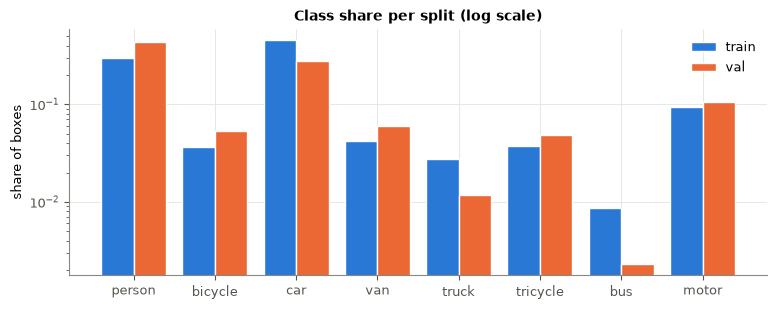

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.2))
Plot.class_bars(counts, ["train", "val"], ax)
ax.set_title("Class share per split (log scale)")
plt.show()

Car (46%) and person (30%) are most of train, while bus is under 1% and truck under 3%, so the classes are very imbalanced and AP for bus and truck will be noisy. Val has a different mix: person is 44% and car only 28%, because with 7 clips a couple of people-only clips change everything. So if we make our own val split by clips, the class mix should be checked and not left to chance

## object size

`sqrt(w * h)` in px

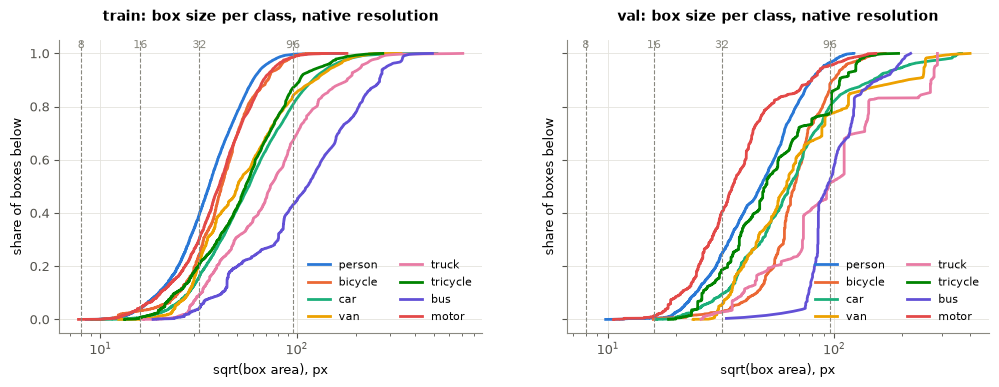

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, s in zip(axes, splits):
    Plot.size_ecdf(s.boxes, ax, title=f"{s.name}: box size per class, native resolution")
plt.show()

In [8]:
pd.concat({s.name: Stats.under(s.boxes) for s in splits}, axis=1)

train                 val              
       <8 px <16 px <32 px <8 px <16 px <32 px
640    0.098  0.542  0.890 0.087  0.484  0.911
1024   0.014  0.203  0.691 0.017  0.163  0.661
1280   0.006  0.098  0.542 0.007  0.087  0.484
1536   0.002  0.046  0.401 0.002  0.060  0.326
native 0.000  0.022  0.249 0.000  0.003  0.192

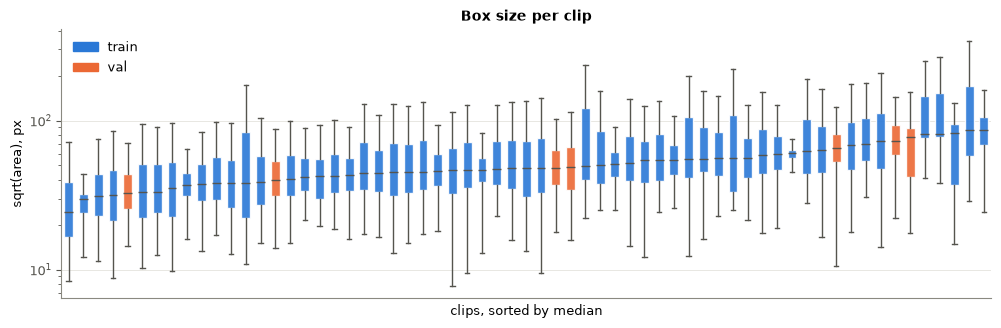

In [9]:
fig, ax = plt.subplots(figsize=(12, 3.5))
Plot.per_clip(boxes, "size", ax, "sqrt(area), px")
ax.set_yscale("log")
ax.set_title("Box size per clip")
plt.show()

Most objects are small: at native resolution 25% of train boxes are under 32 px, and person, bicycle and motor are the smallest. After resizing it gets much worse: at 640 long side 54% of boxes are under 16 px, at 1280 it is 10% and at 1536 under 5%. So the default 640 input of yolo loses about half of the objects, and the input should be at least 1280 or the frame should be cut into tiles

## Shapes and anchors

In [10]:
Stats.aspect(train.boxes)

,ar p10,ar median,ar p90,median w,median h
name,,,,,
person,0.370,0.500,0.760,25.000,50.000
bicycle,0.510,0.950,1.750,43.000,43.000
car,0.820,1.250,2.450,67.000,48.000
van,0.710,1.110,1.960,55.000,46.000
truck,0.770,1.080,2.250,79.000,68.000
tricycle,0.680,1.060,1.840,59.000,51.000
bus,0.620,1.030,2.930,121.000,103.000
motor,0.510,0.800,1.550,38.000,43.000


In [11]:
def model_wh(b):
    k = np.minimum(800 / np.minimum(b["width"], b["height"]), 1333 / np.maximum(b["width"], b["height"]))
    return b[["w", "h"]].to_numpy() * k.to_numpy()[:, None]


wh_tr, wh_va = model_wh(train.boxes), model_wh(val.boxes)
anchors = {"faster r-cnn default": Stats.default_anchors("frcnn"),
           "retinanet default": Stats.default_anchors("retinanet"),
           "kmeans 9": Stats.kmeans(wh_tr, 9), "kmeans 15": Stats.kmeans(wh_tr, 15)}
fit = pd.DataFrame({k: {"shapes": len(a), **Stats.anchor_fit(wh_va, a, thr=(0.4, 0.5, 0.7))}
                    for k, a in anchors.items()}).T
fit

,shapes,mean best iou,>=0.4,>=0.5,>=0.7
faster r-cnn default,15.000,0.622,0.849,0.800,0.429
retinanet default,45.000,0.689,0.849,0.801,0.675
kmeans 9,9.000,0.717,0.986,0.946,0.595
kmeans 15,15.000,0.765,0.992,0.981,0.779


In [12]:
pd.DataFrame(anchors["kmeans 9"].round(1), columns=["w", "h"]).T

,0,1,2,3,4,5,6,7,8
w,11.900,16.100,25.200,33.600,24.500,52.500,45.500,82.600,116.900
h,16.900,31.500,20.300,32.200,48.300,28.700,58.100,44.100,86.100


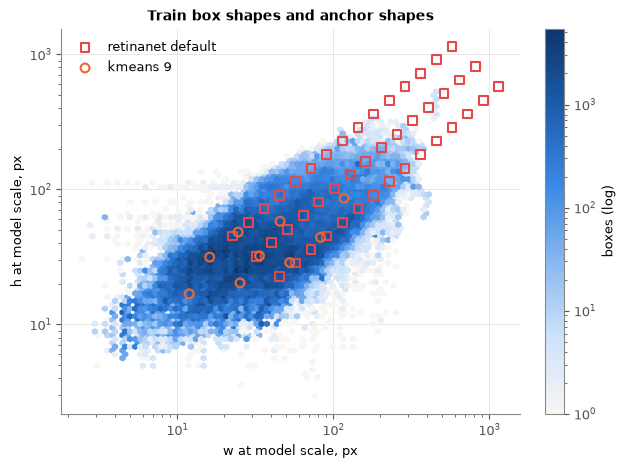

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5))
hb = ax.hexbin(wh_tr[:, 0], wh_tr[:, 1], gridsize=70, xscale="log", yscale="log", bins="log", cmap=BLUES,
               mincnt=1)
for name, a, m in [("retinanet default", anchors["retinanet default"], "s"), ("kmeans 9", anchors["kmeans 9"], "o")]:
    ax.scatter(a[:, 0], a[:, 1], marker=m, s=40, facecolor="none", edgecolor=COLORS[1 if m == "o" else 7],
               linewidth=1.5, label=name)
ax.set_xlabel("w at model scale, px")
ax.set_ylabel("h at model scale, px")
ax.set_title("Train box shapes and anchor shapes")
ax.legend(loc="upper left")
plt.colorbar(hb, ax=ax, fraction=0.04, label="boxes (log)")
plt.show()

Person boxes are tall, car boxes are wide, the rest are close to square. At the scale faster r-cnn works at the default anchors reach iou >= 0.5 for 80% of val boxes, kmeans with 9 shapes gets 95% and with 15 shapes 98%,so anchors from kmeans fit much better even with fewer shapes, mostly because the default anchors start at 32 px and a lot of boxes are smaller than that

## scene density and crowding


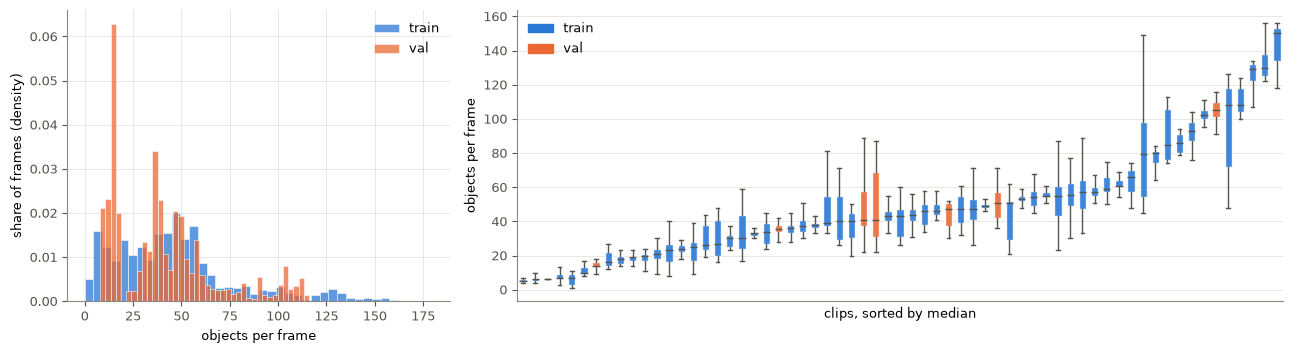

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2]})
for s in splits:
    Plot.hist(s.images["n_obj"], axes[0], bins=40, color=SPLIT_COLORS[s.name], label=s.name, density=True)
axes[0].set_xlabel("objects per frame")
axes[0].set_ylabel("share of frames (density)")
axes[0].legend()
Plot.per_clip(images, "n_obj", axes[1], "objects per frame")
plt.tight_layout()
plt.show()

In [15]:
boxes["crowd"] = np.concatenate([Stats.crowding(s).to_numpy() for s in splits])
crowd = boxes.groupby(boxes["cls"].map(lambda c: CLASSES[c]))["crowd"].agg(
    **{"iou>0.3": lambda v: (v > 0.3).mean(), "iou>0.5": lambda v: (v > 0.5).mean(),
       "iou>0.7": lambda v: (v > 0.7).mean()}).reindex(CLASSES)
crowd.loc["all"] = [(boxes["crowd"] > t).mean() for t in (0.3, 0.5, 0.7)]
crowd

,iou>0.3,iou>0.5,iou>0.7
cls,,,
person,0.237,0.067,0.009
bicycle,0.365,0.090,0.009
car,0.069,0.008,0.001
van,0.049,0.006,0.002
truck,0.055,0.011,0.001
tricycle,0.106,0.014,0.000
bus,0.016,0.000,0.000
motor,0.270,0.083,0.012
all,0.151,0.037,0.005


The number of objects goes from a few to 180 per frame and depends mostly on the clip. some clips always have under 10 objects, others always over 100.nms at iou 0.5 across classes would delete correct boxes, nms should be done per class

## Ignored regions

How many frames have ignored regions, how much of the frame they cover and how many gt boxes
have their centre inside one.

In [16]:
rows = {}
for s in splits:
    cover, inside = Stats.ignore_cover(s)
    s.images["cover"] = cover.to_numpy()
    rows[s.name] = {"frames with ignore": (s.images["n_ignore"] > 0).mean(),
                    "regions per frame": s.images["n_ignore"].mean(),
                    "mean cover": cover.mean(), "p95 cover": cover.quantile(0.95), "max cover": cover.max(),
                    "boxes centred inside": inside.mean()}
pd.DataFrame(rows).T

,frames with ignore,regions per frame,mean cover,p95 cover,max cover,boxes centred inside
train,0.747,2.638,0.026,0.106,0.391,0.011
val,0.504,1.404,0.017,0.087,0.107,0.011


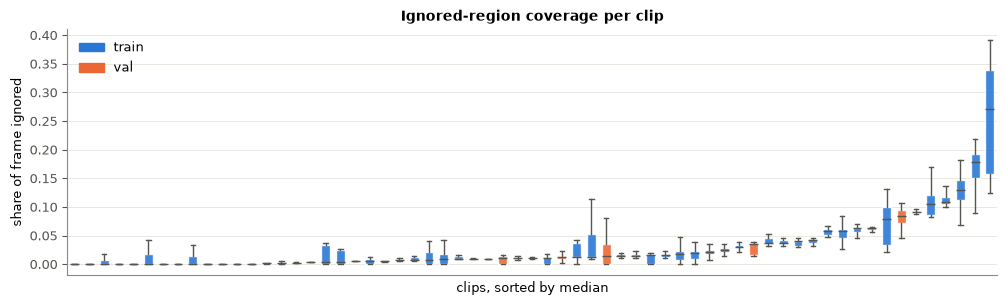

In [17]:
images["cover"] = np.concatenate([s.images["cover"].to_numpy() for s in splits])
fig, ax = plt.subplots(figsize=(12, 3.2))
Plot.per_clip(images, "cover", ax, "share of frame ignored")
ax.set_title("Ignored-region coverage per clip")
plt.show()

75% of train frames and 50% of val frames have ignored regions, but on average they cover only 2.6% of the frame and only 1.1% of boxes have their centre inside one. In a few clips they take 10-30% of the frame (dense parking and crowds). Detections there are not scored, so in training these regions should be greyed out or left out of the loss, otherwise the model is punished for finding real objects that were just not labelled

## Occlusion and truncation

In [18]:
Stats.occlusion(train.boxes)

occlusion               truncation
              none partial heavy  truncated
cls                                        
person       0.541   0.396 0.063      0.020
bicycle      0.465   0.501 0.034      0.008
car          0.570   0.384 0.046      0.057
van          0.571   0.404 0.025      0.042
truck        0.353   0.489 0.158      0.112
tricycle     0.409   0.570 0.021      0.046
bus          0.559   0.420 0.021      0.138
motor        0.547   0.390 0.063      0.031

About 40% of boxes are partly occluded (up to 57% for tricycle), heavy occlusion is rare except for trucks (16%). Trucks and buses are also cut by the frame border the most (11-14%), since they are big. So these two classes will probably be among the failure cases together with the small ones

## Temporal structure

The same object (same `track_id`) in frame t and t + step: median iou and centre shift. Then the
camera motion between consecutive frames per clip (ORB + RANSAC homography), next to the
median object shift of that clip.

In [19]:
shift = pd.concat({s.name: Stats.track_shift(s.boxes) for s in splits})
shift

pairs  iou median  iou<0.5  shift px  shift/size
      step                                                    
train 1     1097628       0.897    0.041     2.000       0.044
      2     1090077       0.810    0.139     3.905       0.085
      4     1075059       0.661    0.332     7.616       0.168
      8     1045470       0.440    0.549    15.042       0.334
      16     989044       0.180    0.703    29.470       0.656
val   1      113284       0.873    0.109     2.500       0.054
      2      112470       0.766    0.232     5.000       0.104
      4      110864       0.592    0.417     9.849       0.205
      8      107728       0.348    0.616    19.313       0.404
      16     101723       0.078    0.776    38.000       0.790

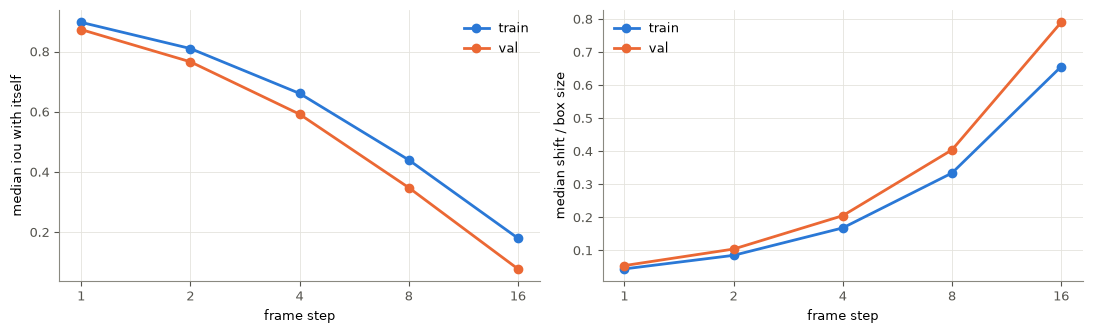

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for name, d in shift.groupby(level=0):
    d = d.droplevel(0)
    axes[0].plot(d.index, d["iou median"], marker="o", color=SPLIT_COLORS[name], label=name)
    axes[1].plot(d.index, d["shift/size"], marker="o", color=SPLIT_COLORS[name], label=name)
for ax, y in zip(axes, ["median iou with itself", "median shift / box size"]):
    ax.set_xscale("log", base=2)
    ax.set_xticks([1, 2, 4, 8, 16], [1, 2, 4, 8, 16])
    ax.set_xlabel("frame step")
    ax.set_ylabel(y)
    ax.legend()
plt.tight_layout()
plt.show()

In [21]:
motion = pd.concat([Stats.camera_motion(s).assign(split=s.name) for s in splits])
obj = pd.concat([Stats.track_shift(s.boxes, steps=(1,), by="clip").droplevel(0) for s in splits])
motion = motion.join(obj[["shift px", "iou median"]].add_prefix("object "))
motion.describe().round(2)

,shift px,inliers,shift % diag,object shift px,object iou median
count,63.000,63.000,63.000,63.000,63.000
mean,2.800,0.900,0.130,2.990,0.870
std,3.620,0.080,0.170,2.340,0.070
min,0.070,0.540,0.000,0.000,0.660
25%,0.590,0.860,0.020,1.500,0.830
50%,1.060,0.920,0.070,2.240,0.880
75%,3.370,0.950,0.160,4.120,0.920
max,16.250,0.990,0.740,12.210,1.000


the same object in two consecutive frames has iou 0.9 and moves about 2 px, the camera itself moves about 1 px per frame in a typical clip. At step 4 the iou is still 0.66, and only at step 16 it drops to 0.18

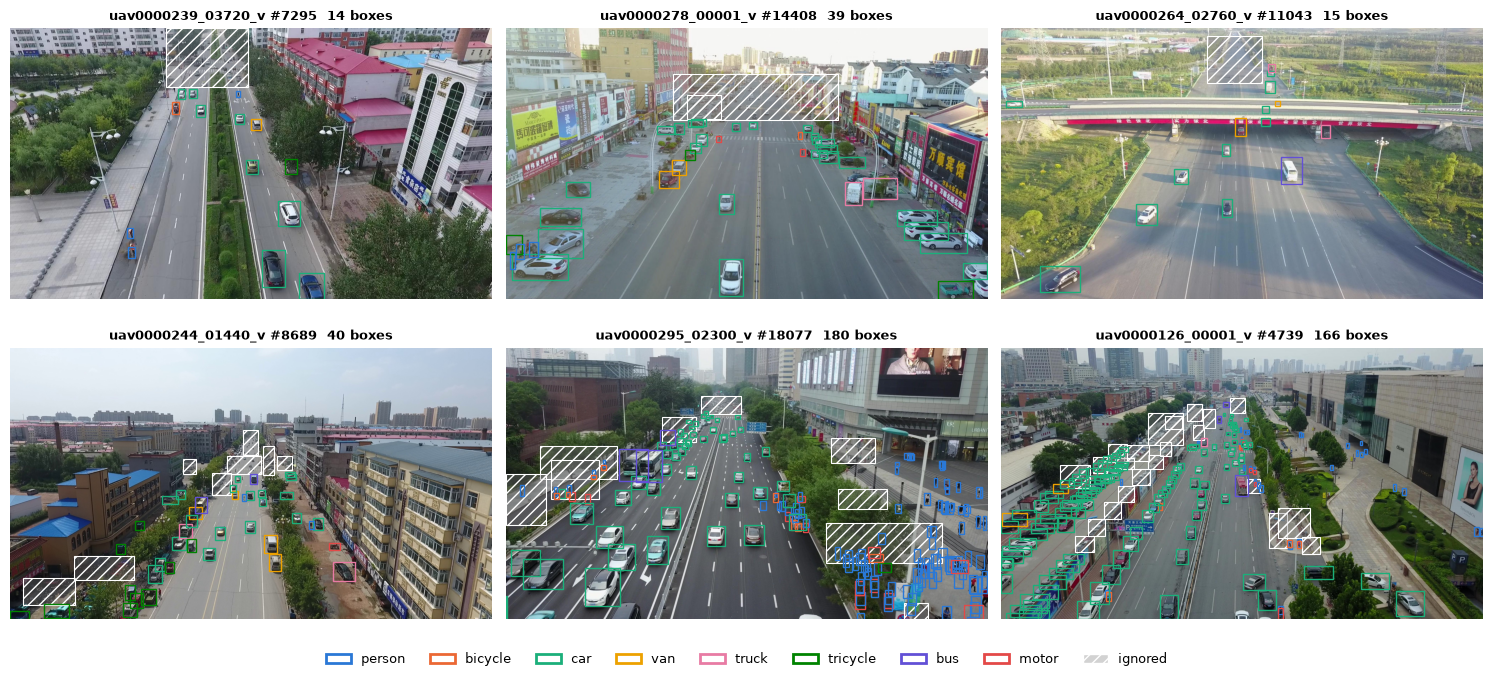

In [22]:
im = train.images
picks = im.groupby(["width", "height"]).sample(1, random_state=0)["image_id"].tolist()[:4]
picks += [im.loc[im["n_obj"].idxmax(), "image_id"], im.loc[im["n_ignore"].idxmax(), "image_id"]]
fig, axes = plt.subplots(2, 3, figsize=(15, 6.8))
for ax, iid in zip(axes.flat, picks):
    Plot.frame(train, iid, ax)
Plot.class_legend(fig)
plt.tight_layout()
plt.show()

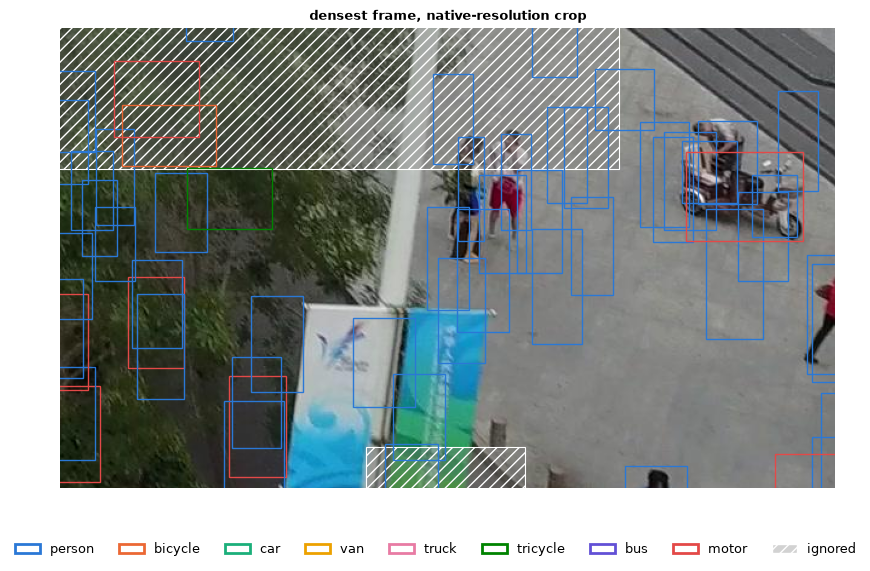

In [23]:
dense = picks[4]
b, _ = train.frame_boxes(dense)
fig, ax = plt.subplots(figsize=(10, 6))
Plot.frame(train, dense, ax, crop=densest_window(b, 640, 380), title="densest frame, native-resolution crop")
Plot.class_legend(fig)
plt.show()

## Decisions

Input of at least 1280 on the long side or tiles, with scale augmentation because test comes in resolutions that train does not have. Anchors for faster r-cnn and retinanet from kmeans instead of the defaults. Train on every 3rd-5th frame, since neighbouring frames are almost the same. Ignored regions masked out in training, nms per class, and our own val split made by clips with a class mix close to train